На практическом занятии мы:
- познакомися с основами [PyTorch](https://pytorch.org/)
- познакомимся с библиотекой [transformers](https://huggingface.co/docs/transformers/index)
- обучим модель BERT для решения задачи классификации текста

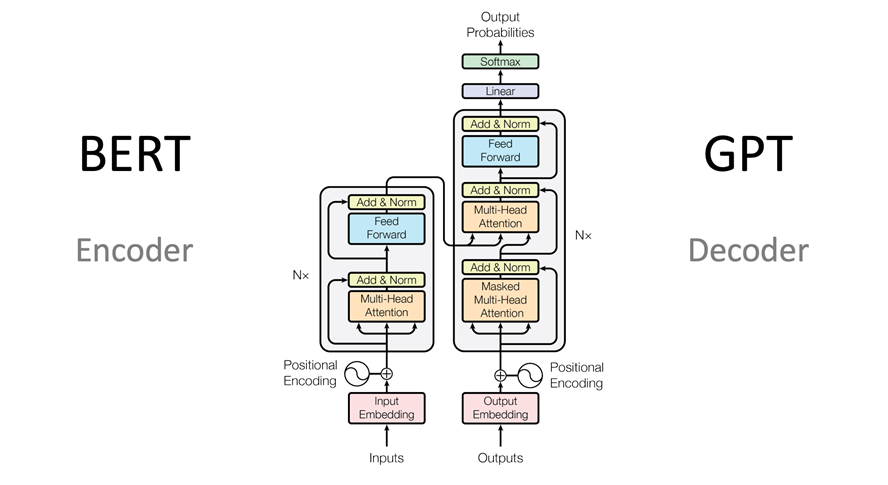

Трансформер состоит из двух блоков:

- **Кодировщик** *(англ. encoder)*: кодировщик получает входные данные и строит их репрезентацию (формирует признаки). Это означает, модель нацелена на "понимание" входных данных.
- **Декодировщик** *(англ. decoder)*: декодировщик использует репрезентации (признаки) кодировщика с другими входными данными для создания нужной последовательности. Это означает, что модель нацелена на генерацию выходных данных.


Каждая из этих частей может быть использована отдельно, это зависит от задачи:

- **Модели-кодировщики**: полезны для задач, требующих *понимания* входных данных, таких как классификация предложений, распознавание именованных сущностей, создание эмбеддингов. `BERT, ALBERT, RoBERTa`
- **Модели-декодировщики**: полезны для генеративных задач, таких как генерация текста. `GPT, Transformer XL`
- **Модели типа “кодировщик-декодировщик”** или **seq2seq-модели**: полезны в генеративных задачах, требующих входных данных. Например: перевод или автоматическое реферирование текста. `BART, T5`

**BERT** (*Bidirectional Encoder Representations from Transformers*), 2018 [статья](https://arxiv.org/pdf/1810.04805)

**GPT** (*Generative Pre-trained Transformer*), 2018 [статья](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)

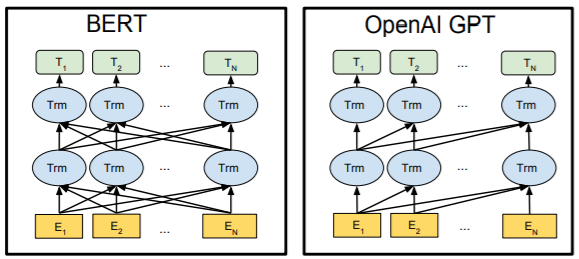

# Данные

[отзывы на фильмы](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews?select=IMDB+Dataset.csv)

In [ ]:
import kagglehub


path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
print("Path to dataset files:", path)

100%|██████████| 25.7M/25.7M [00:02<00:00, 11.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1


In [ ]:
import os


files = os.listdir(path)
files

['IMDB Dataset.csv']

In [ ]:
import pandas as pd


df = pd.read_csv(os.path.join(path, files[0]))
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [ ]:
# датасет сбалансирован
df.groupby(['sentiment']).count()

,review
sentiment,
negative,25000
positive,25000


Равномерно разделим выборку на `train, val, test`

Закодируем `positive` - 0, `negative` - 1

In [ ]:
data = df.copy(deep=True)
data["sentiment"] = df["sentiment"].apply(lambda x: int(x != "positive"))
data.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,0
1,A wonderful little production. <br /><br />The...,0
2,I thought this was a wonderful way to spend ti...,0
3,Basically there's a family where a little boy ...,1
4,"Petter Mattei's ""Love in the Time of Money"" is...",0


In [ ]:
from sklearn.model_selection import train_test_split


train_data, val_data = train_test_split(data, test_size=0.4, random_state=42)
val_data, test_data = train_test_split(val_data, test_size=0.5, random_state=42)

len(train_data), len(val_data), len(test_data)

(30000, 10000, 10000)

In [ ]:
train_data.groupby(['sentiment']).count()

,review
sentiment,
0,14989
1,15011


In [ ]:
val_data.groupby(['sentiment']).count()

,review
sentiment,
0,4990
1,5010


In [ ]:
test_data.groupby(['sentiment']).count()

,review
sentiment,
0,5021
1,4979


# PyTorch


In [ ]:
# в Google Colab пакеты уже установлены
# torchvision torchaudio - для работы с добавляют готовые инструменты для работы с изображениями, видео и звуком

!pip install torch torchvision torchaudio

In [ ]:
# проверка установки
import torch


print(torch.__version__, torch.cuda.is_available())

2.14.1+cu130 True


## Тензоры

`torch.Tensor` - многомерные массивы чисел одного типа (аналог `np.ndarray`), поддерживающие вычисления на CPU/GPU и автоматическое дифференцирование

In [ ]:
import numpy as np


# создание тензора из списка Python
a = torch.tensor([1, 2, 3])
print(f"{a = }")

# создание тензора из массива numpy
arr = np.array([4, 5, 6])
b = torch.from_numpy(arr)
print(f"{b = }")

a = tensor([1, 2, 3])
b = tensor([4, 5, 6])


In [ ]:
# типы данных
# в torch по умолчанию используется fp32
# в numpy по умолчанию используется fp64

a = torch.randn(2, 3)
b = np.random.randn(2, 3)

print(f"{a.dtype = }")
print(f"{b.dtype = }")

# при создании тензора можно указать тип данных
x = torch.tensor([1, 2, 3], dtype=torch.float64)
print(f"{x.dtype = }")

a.dtype = torch.float32
b.dtype = dtype('float64')
x.dtype = torch.float64


In [ ]:
# при создании из numpy будет fp64
arr = np.array([4.0, 5, 6])
b = torch.from_numpy(arr)

print(f"{arr.dtype = }")
print(f"{b.dtype = }")

arr.dtype = dtype('float64')
b.dtype = torch.float64


In [ ]:
# основные атрибуты тензора

t = torch.rand(3, 4)

print(f"{t.shape = }")
print(f"{t.dtype = }")
print(f"{t.device = }")

t.shape = torch.Size([3, 4])
t.dtype = torch.float32
t.device = device(type='cpu')


In [ ]:
# проверка доступности GPU
torch.cuda.is_available()

True

In [ ]:
# перемещение тензора на GPU

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

x = torch.randn(2, 3)  # создан на CPU

# не in-place операция
x = x.to(device) # или x.cuda()
x.device

device(type='cuda', index=0)

In [ ]:
x

tensor([[-0.9936,  0.0196, -1.2523],
        [-0.8508,  1.9075, -0.5999]])

In [ ]:
# тензоры поддерживают обращения по индексам и срезам
x[0][0]

tensor(-0.9936)

In [ ]:
# метод .item() для получения именно значения
x[0][0].item()

-0.9935731291770935

In [ ]:
# произведение векторов
a = torch.tensor([1., 2.])
b = torch.tensor([3., 4.])

print(a @ b)
a.dot(b)

tensor(11.)


tensor(11.)

In [ ]:
# произведение матриц
A = torch.tensor([
    [1., 2.],
    [3., 4.]
])
B = torch.tensor([
    [5., 6.],
    [7., 8.]
])

print(A @ B)
torch.mm(A, B)

tensor([[19., 22.],
        [43., 50.]])


tensor([[19., 22.],
        [43., 50.]])

**Стандартные конструкторы**

In [ ]:
# размер можно передавать кортежем torch.ones((2, 3)) или отдельными аргументами torch.ones(2, 3)

torch.zeros(2, 3)

tensor([[0., 0., 0.],
        [0., 0., 0.]])

In [ ]:
torch.ones(2, 3)

tensor([[1., 1., 1.],
        [1., 1., 1.]])

In [ ]:
# создать по размерности существующего тензора
x = torch.zeros(2, 3)
torch.ones_like(x)

tensor([[1., 1., 1.],
        [1., 1., 1.]])

In [ ]:
# создать по размерности существующего тензора
x = torch.ones(3, 2)
torch.zeros_like(x)

tensor([[0., 0.],
        [0., 0.],
        [0., 0.]])

In [ ]:
# uniform [0, 1)
torch.rand(2, 3)

tensor([[0.2558, 0.7002, 0.4986],
        [0.2287, 0.8093, 0.5868]])

In [ ]:
# standard normal
torch.randn(2, 3)

tensor([[ 0.9461,  1.0048,  1.4970],
        [-0.2703,  0.3604,  1.2559]])

In [ ]:
torch.eye(3)

tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])

In [ ]:
torch.arange(10)

tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
torch.linspace(-2, 2, steps=11)

tensor([-2.0000e+00, -1.6000e+00, -1.2000e+00, -8.0000e-01, -4.0000e-01,
        -2.9802e-08,  4.0000e-01,  8.0000e-01,  1.2000e+00,  1.6000e+00,
         2.0000e+00])

In [ ]:
torch.full((2, 3), 3)

tensor([[3, 3, 3],
        [3, 3, 3]])

## Автоматическое дифференцирование


- Каждая операция над тензорами (сложение, умножение, sin, свертка и т.д.) - это **элементарная** дифференцируемая функция
- PyTorch запоминает все выполненные операции в виде **графа вычислений**: узлы - операции, ребра - тензоры
- Чтобы посчитать производную сложной функции по любому входу, PyTorch проходит
граф в **обратную сторону**, применяя правило дифференцирования сложной
функции

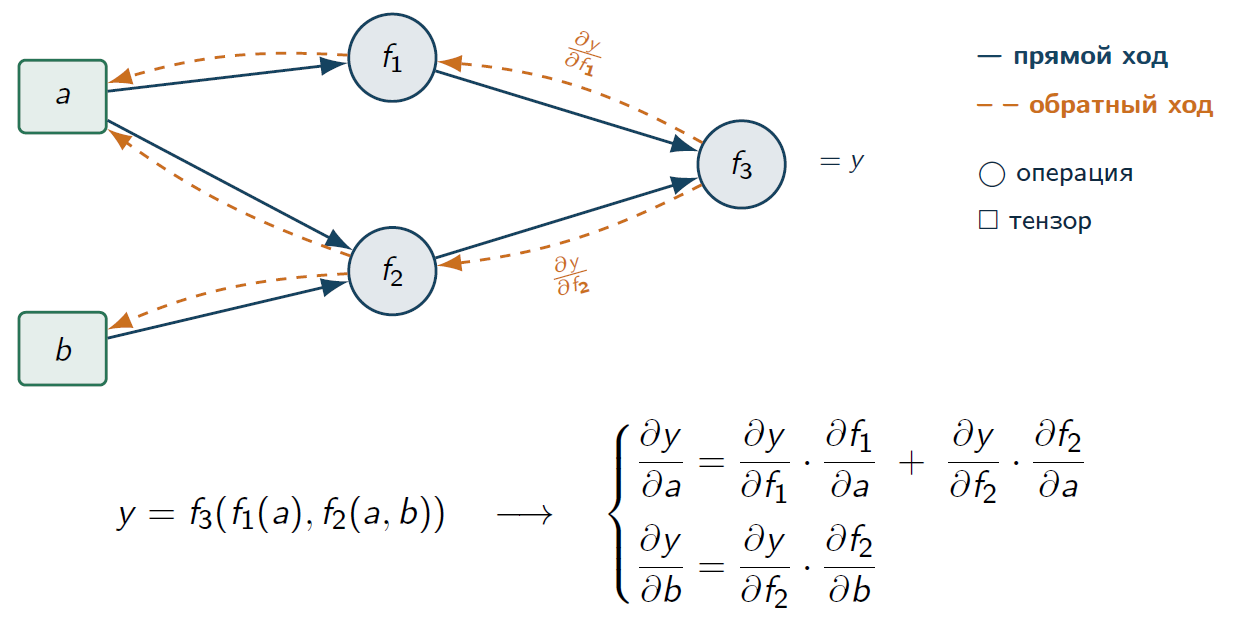

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

z = x**2 + y**3

print(z.requires_grad)
print(z.grad_fn)

True


**Граф вычислений для функции**: `z = x**2 + y**3`

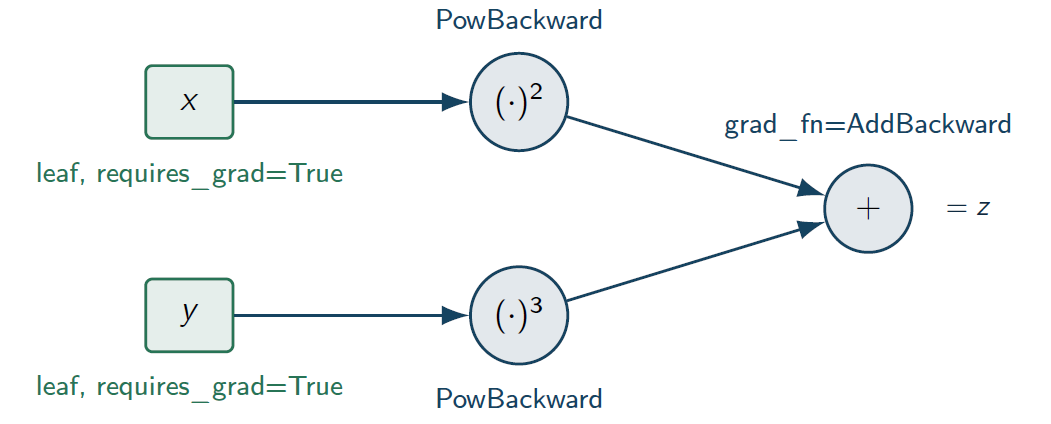

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

z = x**2 + y**3 + x*y

z.backward()    # считается dz/dx и dz/dy

# тензоры, созданные с флагом `requires_grad = True` - листья
# в их .grad накапливается результат

print(x.grad)   # 2x + y == 4 + 3
print(y.grad)   # 3y^2 + x == 27 + 2

tensor(7.)
tensor(29.)


В **PyTorch** при каждом вызове `.backward()` новые градиенты прибавляются к тем, что уже лежат в атрибуте `.grad`, а не перезаписывают их

In [ ]:
z = x**2 + y**3 + x*y

z.backward()

print(x.grad)   # должно быть 7
print(y.grad)   # должно быть 29

tensor(14.)
tensor(58.)


Свойство `.grad` - это "копилка". **PyTorch** специально проектировали так, чтобы `.backward()` делал `+=`, а не `=`. Это удобно для рекуррентных сетей и сложных моделей с несколькими выходами

In [ ]:
# Обнуляем градиенты вручную
x.grad.zero_()
y.grad.zero_()

z = x**2 + y**3 + x*y

z.backward()

print(x.grad)
print(y.grad)

tensor(7.)
tensor(29.)


In [ ]:
# сделать повторный .backward() не получится
# по умолчанию граф вычислений уничтожается сразу после первого backward() - ради экономии памяти
z.backward()

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

z = x**2 + y**3 + x*y

z.backward(retain_graph=True)

print(x.grad)
print(y.grad)

tensor(7.)
tensor(29.)


In [ ]:
# получается, но не спасает нас от накопления градиентов
z.backward()
print(x.grad)
print(y.grad)

tensor(14.)
tensor(58.)


In [ ]:
# .backward() без аргументов работает только для скалярного z

x = torch.tensor([1., 2., 3.], requires_grad=True)
y = x**2
y.backward()

Для подсчёта вектора значений производной функции можно использовать произведение матрицы на вектор


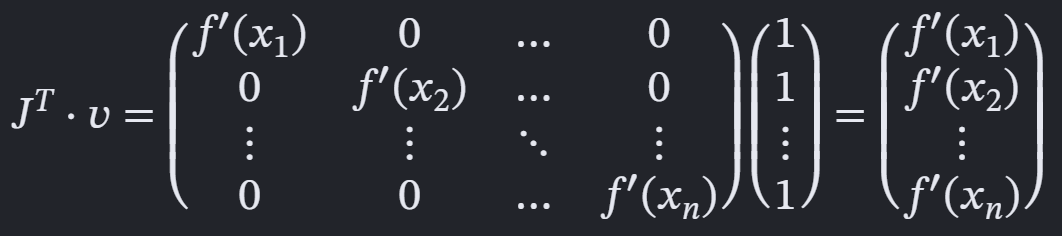

Это перестанет работать, если в матрице будут внедиагональные элементы, то есть такой трюк работает только с функциями, которые применяются к каждому отдельному элементу массива: `torch.sum(x), torch.mean(x)`

In [ ]:
x = torch.tensor([1., 2., 3.] , requires_grad=True)
y = x**2

v = torch.ones_like(x)
print(f"{v = }")

y.backward(gradient=v)
x.grad

v = tensor([1., 1., 1.])


tensor([2., 4., 6.])

Производные высших порядков
- по умолчанию граф вычислений для самих градиентов не строится.
- флаг `create_graph=True` заставляет **PyTorch** построить граф и для операции взятия градиента - тогда ее тоже можно дифференцировать

In [ ]:
x = torch.tensor(3.0, requires_grad=True)
y = x**3

grad1 = torch.autograd.grad(y, x, create_graph=True)[0] # grad1 = 3x^2 = 27
print(grad1)

grad2 = torch.autograd.grad(grad1, x)[0] # grad2 = 6x = 18
print(grad2)

tensor(27., grad_fn=<MulBackward0>)
tensor(18.)


In [ ]:
# когда производные не нужны
x = torch.tensor(2.0, requires_grad=True)

with torch.no_grad():
    y = x**2
    print(y.requires_grad)

z = x.detach()
z

False


tensor(2.)

In [ ]:
import numpy as np
import torch


x = torch.linspace(0, 2*np.pi, steps=360, requires_grad=True)
sin_x = torch.sin(x)

v = torch.ones_like(x)
d_sin_x = torch.autograd.grad(sin_x, x, grad_outputs=v)[0]

cos_x = torch.cos(x)

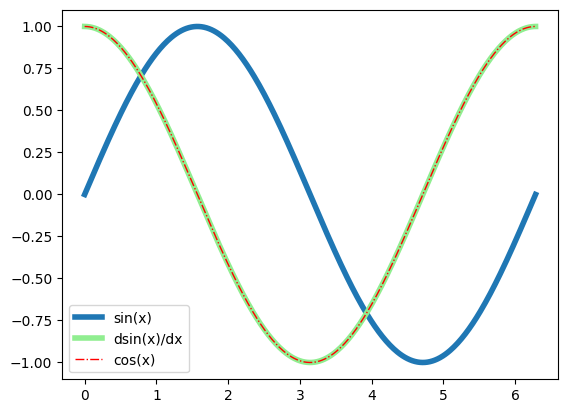

In [ ]:
import matplotlib.pyplot as plt


plt.plot(x.tolist(), sin_x.tolist(), linewidth=4, label="sin(x)")
plt.plot(x.tolist(), d_sin_x.tolist(), color="lightgreen", linewidth=4, label="dsin(x)/dx")
plt.plot(x.tolist(), cos_x.tolist(), color="red", linewidth=1, linestyle="-.", label="cos(x)")

plt.legend()
plt.show()

In [ ]:
x = torch.linspace(-2, 2, steps=100, requires_grad=True)
y = x**3

v = torch.ones_like(x)
d_y = torch.autograd.grad(y, x, create_graph=True, grad_outputs=v)[0]
d_y_2 = torch.autograd.grad(d_y, x, grad_outputs=v)[0]

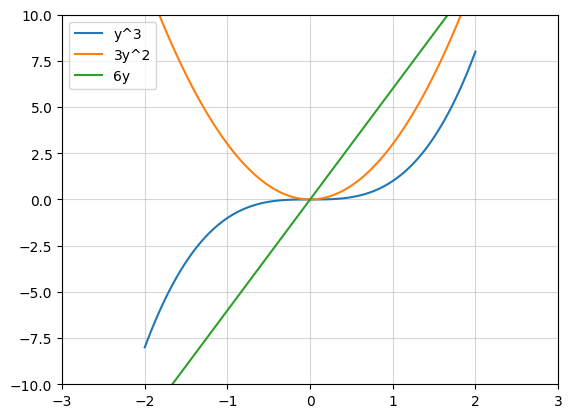

In [ ]:
plt.plot(x.tolist(), y.tolist(), label="y^3")
plt.plot(x.tolist(), d_y.tolist(), label="3y^2")
plt.plot(x.tolist(), d_y_2.tolist(), label="6y")

plt.xlim(-3, 3)
plt.ylim(-10, 10)

plt.legend()
plt.grid(alpha=0.5)
plt.show()

## Нейронные сети

`nn.Module`: базовый класс всех моделей

- любой слой, любой блок, любая модель в **PyTorch** - наследник класса torch.nn.Module
- `nn.Module` отвечает за учёт обучаемых параметров, перемещение между CPU/GPU, сохранение/загрузку модели, переключение режимов обучения/инференса
- как правило, требуется реализовать только конструктор (`__init__`) и прямой проход (`forward`)

$$\hat{y} = \sigma(X W_1^T + b_1) W_2^T + b_2$$

In [ ]:
import torch
from torch import nn


class SimpleLinear(nn.Module):
    def __init__(self, in_dim, hid_dim, out_dim):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hid_dim, bias=True)
        self.act = nn.Sigmoid()
        self.fc2 = nn.Linear(hid_dim, out_dim, bias=True)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x


X = torch.randn(10, 64)

model = SimpleLinear(64, 256, 2)

# для получения предсказаний передаём матрицу в метод __call__() модели
preds = model(X)
preds

tensor([[0.1579, 0.8280],
        [0.2223, 0.5888],
        [0.2190, 0.7779],
        [0.2239, 0.7013],
        [0.1798, 0.6144],
        [0.1631, 0.6968],
        [0.0663, 0.6978],
        [0.3398, 0.5470],
        [0.0975, 0.7587],
        [0.0906, 0.6109]], grad_fn=<AddmmBackward0>)

In [ ]:
nn.functional.softmax(preds, dim=-1)

tensor([[0.3385, 0.6615],
        [0.4094, 0.5906],
        [0.3638, 0.6362],
        [0.3829, 0.6171],
        [0.3930, 0.6070],
        [0.3697, 0.6303],
        [0.3472, 0.6528],
        [0.4484, 0.5516],
        [0.3405, 0.6595],
        [0.3728, 0.6272]], grad_fn=<SoftmaxBackward0>)

In [ ]:
torch.argmax(preds, dim=-1)

tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

# transformers

In [ ]:
!pip install transformers

Общий [пайплайн](https://huggingface.co/learn/llm-course/ru/chapter2/2) работы

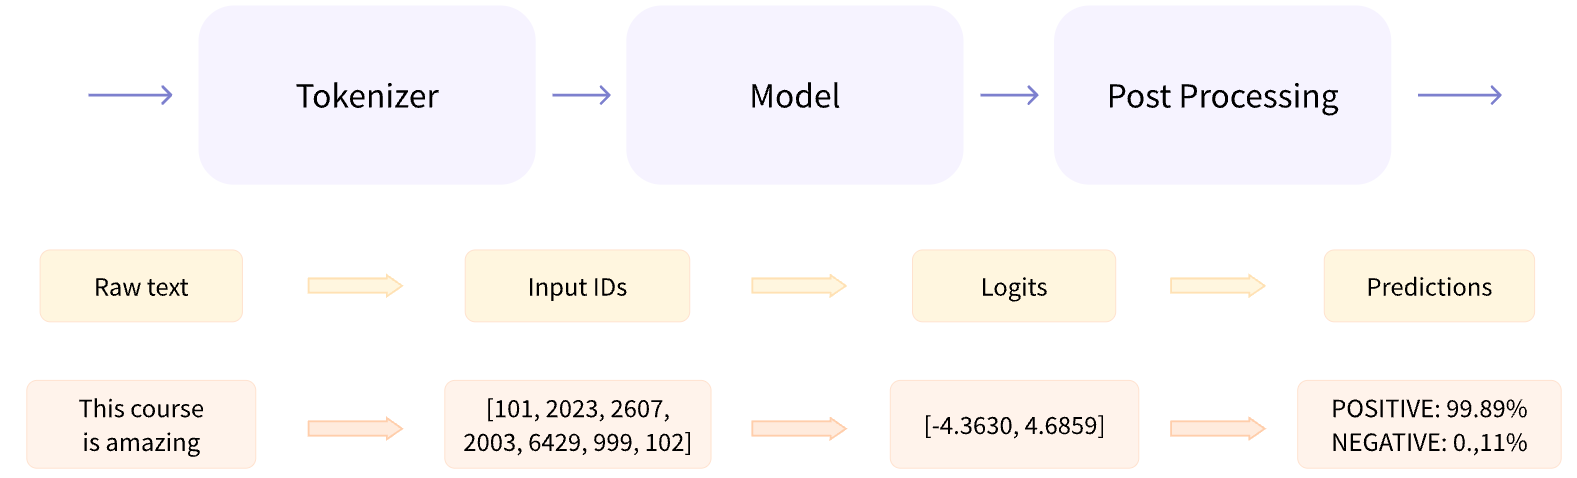

Загрузим модель и токенизатор с помощью generic-классов (`Auto`-классы).

In [ ]:
from transformers import AutoModel, AutoTokenizer


model_ckpt = "distilbert-base-uncased-finetuned-sst-2-english"

model = AutoModel.from_pretrained(model_ckpt)
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

## Токенизатор

In [ ]:
tokenizer

BertTokenizer(name_or_path='distilbert-base-uncased-finetuned-sst-2-english', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [ ]:
sentences = [
    "Using a Transformer network is simple",
    "The quick brown fox jumps over the lazy dog",
]

`input_ids` - уникальные идентификаторы токенов

`token_type_ids` - принадлежность токена к предложению

`attention_mask` - маска внимания

In [ ]:
# передаём в метод __call__()
inputs = tokenizer(sentences[0])
inputs

# for k, v in inputs.items():
#     print(k)
#     print(v)
#     print()

{'input_ids': [101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
for i, (k, v) in enumerate(tokenizer.vocab.items()):
    if i == 10:
        break
    print(f"{k}: {v}")

##ony: 16585
kings: 5465
##thorpe: 22398
been: 2042
canned: 27141
sake: 8739
##aka: 11905
247: 23380
bears: 6468
dolores: 21544


In [ ]:
# кодирование = токенизация + преобразование токенов во входные идентификаторы
print(sentences[0])

# токенизация
tokens = tokenizer.tokenize(sentences[0])
print(tokens)

# преобразование токенов во входные идентификаторы
ids = tokenizer.convert_tokens_to_ids(tokens)
print(ids)

Using a Transformer network is simple
['using', 'a', 'transform', '##er', 'network', 'is', 'simple']
[2478, 1037, 10938, 2121, 2897, 2003, 3722]


In [ ]:
# ещё один способ
tokenizer.encode(sentences[0])

[101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102]

In [ ]:
# декодирование
print(tokenizer.decode(inputs))
print(tokenizer.decode(ids))

[CLS] using a transformer network is simple [SEP]
using a transformer network is simple


In [ ]:
# несколько строк разными аргументами
inputs = tokenizer(*sentences)
inputs

{'input_ids': [101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102, 1996, 4248, 2829, 4419, 14523, 2058, 1996, 13971, 3899, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
# несколько строк одним батчем
inputs = tokenizer(sentences)
inputs

for k, v in inputs.items():
    print(k)
    print(v)
    print()

input_ids
[[101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102], [101, 1996, 4248, 2829, 4419, 14523, 2058, 1996, 13971, 3899, 102]]

token_type_ids
[[0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]

attention_mask
[[1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]



In [ ]:
inputs.input_ids

[[101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102],
 [101, 1996, 4248, 2829, 4419, 14523, 2058, 1996, 13971, 3899, 102]]

In [ ]:
# паддинг
inputs = tokenizer(sentences, padding=True)
inputs.input_ids

[[101, 2478, 1037, 10938, 2121, 2897, 2003, 3722, 102, 0, 0],
 [101, 1996, 4248, 2829, 4419, 14523, 2058, 1996, 13971, 3899, 102]]

In [ ]:
# модели transformers принимают на вход только тензоры
inputs = tokenizer(sentences, padding=True, return_tensors="pt")
inputs

{'input_ids': tensor([[  101,  2478,  1037, 10938,  2121,  2897,  2003,  3722,   102,     0,
             0],
        [  101,  1996,  4248,  2829,  4419, 14523,  2058,  1996, 13971,  3899,
           102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [ ]:
inputs["input_ids"]

tensor([[  101,  2478,  1037, 10938,  2121,  2897,  2003,  3722,   102,     0,
             0],
        [  101,  1996,  4248,  2829,  4419, 14523,  2058,  1996, 13971,  3899,
           102]])

In [ ]:
inputs["attention_mask"]

tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

## Модель

In [ ]:
model

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
import torch
from torch import nn


# слой для получения эмбеддингов по индексам токенов
lookup_table = nn.Embedding(100, 12)
lookup_table

Embedding(100, 12)

In [ ]:
# передаём тензоры индексов токенов
lookup_table(torch.tensor(0))

tensor([-0.7029,  0.6221, -2.2782, -1.3317, -1.0882,  0.0985,  1.5570,  1.0215,
         0.1030,  0.3619, -1.2364, -0.9869], grad_fn=<EmbeddingBackward0>)

In [ ]:
lookup_table(torch.tensor([0, 1, 2]))

tensor([[-0.7029,  0.6221, -2.2782, -1.3317, -1.0882,  0.0985,  1.5570,  1.0215,
          0.1030,  0.3619, -1.2364, -0.9869],
        [ 0.6919, -0.6602,  0.2039, -0.4656,  0.5021, -2.3815,  0.3246, -0.2708,
          1.2933,  1.8106, -1.5753, -0.5554],
        [ 1.8353, -1.3164, -0.3113, -0.7711, -0.6125,  0.6741,  0.2304,  0.6849,
         -0.4007, -0.1895, -0.7462,  0.8547]], grad_fn=<EmbeddingBackward0>)

In [ ]:
# обращение к конкретным слоям
for name, par in model.named_parameters():
    print(name)

embeddings.word_embeddings.weight
embeddings.position_embeddings.weight
embeddings.LayerNorm.weight
embeddings.LayerNorm.bias
transformer.layer.0.attention.q_lin.weight
transformer.layer.0.attention.q_lin.bias
transformer.layer.0.attention.k_lin.weight
transformer.layer.0.attention.k_lin.bias
transformer.layer.0.attention.v_lin.weight
transformer.layer.0.attention.v_lin.bias
transformer.layer.0.attention.out_lin.weight
transformer.layer.0.attention.out_lin.bias
transformer.layer.0.sa_layer_norm.weight
transformer.layer.0.sa_layer_norm.bias
transformer.layer.0.ffn.lin1.weight
transformer.layer.0.ffn.lin1.bias
transformer.layer.0.ffn.lin2.weight
transformer.layer.0.ffn.lin2.bias
transformer.layer.0.output_layer_norm.weight
transformer.layer.0.output_layer_norm.bias
transformer.layer.1.attention.q_lin.weight
transformer.layer.1.attention.q_lin.bias
transformer.layer.1.attention.k_lin.weight
transformer.layer.1.attention.k_lin.bias
transformer.layer.1.attention.v_lin.weight
transformer.lay

In [ ]:
# передаём в метод __call__()
outputs = model(**inputs)
outputs

BaseModelOutput(last_hidden_state=tensor([[[ 0.0315, -0.1062,  0.6005,  ...,  0.2884, -0.0817,  0.4607],
         [ 0.1002,  0.0225,  0.0025,  ...,  0.1821, -0.1360,  0.5374],
         [-0.1373, -0.1224,  0.3197,  ...,  0.4080, -0.3323,  0.7868],
         ...,
         [ 0.8455, -0.1279,  0.2845,  ...,  0.8325, -0.2727,  0.0144],
         [ 0.2379, -0.3000,  0.3425,  ...,  0.1677,  0.0551,  0.6716],
         [ 0.2504, -0.4067,  0.4033,  ...,  0.1414,  0.0392,  0.6220]],

        [[-0.5557,  0.1112,  0.0999,  ..., -0.7762,  0.7737,  0.0843],
         [-0.9640,  0.1964, -0.2217,  ..., -0.4896,  1.1340, -0.1048],
         [-0.6650,  0.1257,  0.0747,  ..., -0.5854,  0.8308,  0.0700],
         ...,
         [-0.3581,  0.5381,  0.3409,  ..., -0.5511,  0.9153, -0.2904],
         [-0.4109,  0.2363, -0.0462,  ..., -0.6289,  0.9136,  0.1036],
         [ 0.2678,  0.3142,  0.1639,  ..., -0.0788,  0.3945, -0.2092]]],
       grad_fn=<NativeLayerNormBackward0>), hidden_states=None, attentions=None)

Вектор, возвращаемый Transformer, обычно имеет три измерения:

- **Размер батча (Batch size)** - Количество последовательностей, обрабатываемых за один раз
- **Длина последовательности (Sequence length)** - Длина числового представления последовательности
- **Скрытый размер (Hidden size)** - Размерность вектора каждого входа модели

In [ ]:
# batch_size x seq_len x hid_size
outputs.last_hidden_state.shape

torch.Size([2, 11, 768])

In [ ]:
inputs.input_ids.shape

torch.Size([2, 11])

Далее выходы Transformer передаются в голову для обработки. Головы модели принимают на вход многомерный вектор скрытых состояний и проецируют его на другое измерение.

| Название класса | Какая голова навешивается? | Что принимает на вход? | Что выдает на выходе? (Shape) | Пример задачи |
| :--- | :--- | :--- | :--- | :--- |
| **`*Model`** | **Головы нет.** Это «тело» модели. | Матрицу токенов текста | Скрытые состояния (`[batch, seq_len, 768]`) | Получение сырых эмбеддингов |
| **`*ForSequenceClassification`** | Линейный слой (`nn.Linear(768, num_labels)`) | Только вектор токена **`[CLS]`** | Логиты классов (`[batch, num_labels]`) | Анализ тональности отзывов |
| **`*ForTokenClassification`** | Линейный слой (`nn.Linear(768, num_labels)`) | Скрытые состояния **всех** токенов | Логиты тегов для каждого слова (`[batch, seq_len, num_labels]`) | Выделение сущностей (NER) |
| **`*ForQuestionAnswering`** | Линейный слой (`nn.Linear(768, 2)`) | Скрытые состояния **всех** токенов | Позиции начала и конца ответа (`[batch, seq_len, 2]`) | Поиск ответа в тексте (SQuAD) |
| **`*ForMaskedLM`** | Проекция на словарь (`nn.Linear(768, vocab_size)`) | Скрытые состояния токенов `[MASK]` | Вероятности слов из словаря (`[batch, seq_len, vocab_size]`) | Предобучение (MLM), автозаполнение |
| **`*ForMultipleChoice`** | Линейный слой (`nn.Linear(768, 1)`) | Векторы `[CLS]` для всех вариантов | Оценку для каждого варианта (`[batch, num_choices]`) | Тесты с выбором ответа (А, Б, В) |

In [ ]:
# было
model

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [ ]:
# для задачи классификации потребуется поставить голову
from transformers import AutoModelForSequenceClassification


model_ckpt = "distilbert-base-uncased-finetuned-sst-2-english"
model = AutoModelForSequenceClassification.from_pretrained(model_ckpt)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [ ]:
# стало
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [ ]:
outputs = model(**inputs)
outputs

SequenceClassifierOutput(loss=None, logits=tensor([[-2.5780,  2.5856],
        [ 0.9437, -0.7582]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

In [ ]:
# логиты для первого и второго предложения
outputs.logits

tensor([[-2.5780,  2.5856],
        [ 0.9437, -0.7582]], grad_fn=<AddmmBackward0>)

In [ ]:
preds = torch.nn.functional.softmax(outputs.logits, dim=-1)
preds

tensor([[0.0057, 0.9943],
        [0.8458, 0.1542]], grad_fn=<SoftmaxBackward0>)

In [ ]:
# dim=-1 --> столбцы --> мы считаем вдоль оси столбцов
# tensor([[-1.5607,  1.6123],
#         [ 4.1692, -3.3464]])
# элемент 0 вдоль оси столбцов == [-1.5607,  1.6123] --> exp(...)
# элемент 1 вдоль оси столбцов == [ 4.1692, -3.3464] --> exp(...)

In [ ]:
torch.argmax(preds, dim=-1)

tensor([1, 0])

In [ ]:
model.config.id2label

{0: 'NEGATIVE', 1: 'POSITIVE'}

In [ ]:
sentences

['Using a Transformer network is simple',
 'The quick brown fox jumps over the lazy dog']

In [ ]:
for sentence, i in zip(sentences, torch.argmax(preds, dim=-1).tolist()):
    print(model.config.id2label[i], sentence)

POSITIVE Using a Transformer network is simple
NEGATIVE The quick brown fox jumps over the lazy dog


In [ ]:
# padding
batched_ids = [
    [200, 200, 200],
    [200, 200],
]

model(torch.tensor(batched_ids))

ValueError: expected sequence of length 3 at dim 1 (got 2)

In [ ]:
# attention mask
sequence1_ids = [[200, 200, 200]]
sequence2_ids = [[200, 200]]

batched_ids = [
    [200, 200, 200],
    [200, 200, tokenizer.pad_token_id],
]

print(model(torch.tensor(sequence1_ids)).logits)
print(model(torch.tensor(sequence2_ids)).logits, end="\n\n")

print(model(torch.tensor(batched_ids)).logits)

tensor([[ 1.5694, -1.3895]], grad_fn=<AddmmBackward0>)
tensor([[ 0.5803, -0.4125]], grad_fn=<AddmmBackward0>)

tensor([[ 1.5694, -1.3895],
        [ 1.3374, -1.2163]], grad_fn=<AddmmBackward0>)


In [ ]:
# нужно использовать маску
batched_ids = [
    [200, 200, 200],
    [200, 200, tokenizer.pad_token_id],
]

attention_mask = [
    [1, 1, 1],
    [1, 1, 0],
]

outputs = model(
    torch.tensor(batched_ids),
    attention_mask=torch.tensor(attention_mask)
)
print(outputs.logits)

tensor([[ 1.5694, -1.3895],
        [ 0.5803, -0.4125]], grad_fn=<AddmmBackward0>)


In [ ]:
# MVP использования токенизатора и модели
with torch.no_grad():
    inputs = tokenizer(sentences, padding=True, truncation=True, return_tensors="pt")
    outputs = model(**inputs)
    preds = torch.nn.functional.softmax(outputs.logits, dim=-1)
    print(preds)

tensor([[0.0057, 0.9943],
        [0.8458, 0.1542]])


# Обучение

Модель [bert-base-uncased](https://huggingface.co/google-bert/bert-base-uncased):
- `bert` - архитектура
- `base` - размер модели 110M параметров. У `large` - 340M
- `uncased` - не понимает разницу между ***e**nglish* и ***E**nglish*

In [ ]:
# если знаем тип модели, то можем напрямую использовать подходящий класс
import torch
from transformers import BertConfig, BertForSequenceClassification, BertTokenizer


checkpoint = "google-bert/bert-base-uncased"
tokenizer = BertTokenizer.from_pretrained(checkpoint)

bert_config = BertConfig(
    vocab_size=tokenizer.vocab_size,
    hidden_size=256,
    num_hidden_layers=4,
    num_attention_heads=4,
    intermediate_size=512,
    num_labels=2
)

model = BertForSequenceClassification(bert_config)   # этот BERT не обучен и инициализирован случайными числами
model

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 256, padding_idx=0)
      (position_embeddings): Embedding(512, 256)
      (token_type_embeddings): Embedding(2, 256)
      (LayerNorm): LayerNorm((256,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=256, out_features=256, bias=True)
              (key): Linear(in_features=256, out_features=256, bias=True)
              (value): Linear(in_features=256, out_features=256, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=256, out_features=256, bias=True)
              (LayerNorm): LayerNorm((256,), e

In [ ]:
MODEL_MAX_LENGTH = tokenizer.model_max_length
MODEL_MAX_LENGTH

512

In [ ]:
model.classifier

Linear(in_features=256, out_features=2, bias=True)

In [ ]:
# подготовка данных для обучения

from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding


# создаем собственный класс датасета для PyTorch, наследуясь от базового класса Dataset.
class IMDBDataset(Dataset):
    def __init__(self, data, tokenizer, max_length):
        super(IMDBDataset, self).__init__()
        self.data = data
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
       """
        Обязательный метод для PyTorch Dataset.
        Возвращает общее количество примеров (строк) в датасете.
        """
        return len(self.data)

    def __getitem__(self, idx):
        """
        Обязательный метод для PyTorch Dataset.
        Получает один конкретный пример по его индексу (idx) и преобразует его в формат для модели.
        """
        text = self.data["review"].iloc[idx]
        label = self.data["sentiment"].iloc[idx]

        encoded = self.tokenizer(
            text,
            max_length=self.max_length,
            padding=False,  # будет выполняться DataCollator-ом
            truncation=True,
            return_tensors="pt",
            return_token_type_ids=False
        )

        encoded["input_ids"] = encoded["input_ids"].squeeze()
        encoded["attention_mask"] = encoded["attention_mask"].squeeze()
        encoded["labels"] = torch.tensor(label, dtype=torch.long)

        return encoded

# реализует "динамический паддинг": находит самый длинный текст в конкретном батче
# и добивает остальные тексты в этом батче токеном pad
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True)

In [ ]:
train_dataset = IMDBDataset(train_data, tokenizer, MODEL_MAX_LENGTH)
val_dataset = IMDBDataset(val_data, tokenizer, MODEL_MAX_LENGTH)
test_dataset = IMDBDataset(test_data, tokenizer, MODEL_MAX_LENGTH)

In [ ]:
next(iter(train_dataset))

{'input_ids': tensor([  101,  1045, 11780,  1006,  3621,  6310,  1007,  2516,  2013,  2070,
         2060,  7615,  1012,  1045,  2031,  2000,  2360,  1010,  2008,  2004,
         1045,  2788,  2123,  1005,  1056,  2066,  3276,  2186,  1010,  1045,
         2428,  2106,  4669,  2023,  2028,  1012,  2307,  3494,  1010,  5875,
         1998,  2025, 18856, 17322,  2466,  1010,  2204,  3772,  1010,  2204,
         1998,  2153,  2025, 18856, 17322,  1006,  2029,  1999,  2553,  1997,
        13764,  8649,  2015,  2003,  2738,  4678,  1007, 13764,  8649,  2015,
         1012,  1012,  1012,  2009,  2003,  2428,  5875,  1010,  2129,  1996,
         3494,  2892, 10425,  2007,  2169,  2060,  1010,  1998,  2823,  4209,
         2135,  1010,  2823,  2062,  2030,  2625,  2012,  6721,  3747,  2169,
         2500,  3268,  1012,  2021,  6854,  1010,  2004,  2057,  2360,  1999,
         2256,  2406,  1011,  2079,  2017,  2113,  2129,  2079,  2017,  6807,
         1037,  2204,  2149,  2186,  1029,  2009, 

In [ ]:
BATCH_SIZE = 256

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
    num_workers=2,
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=2,
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
    num_workers=2,
)

In [ ]:
tmp = next(iter(train_dataloader))
tmp

{'input_ids': tensor([[  101, 19838,  5620,  ...,     0,     0,     0],
        [  101,  1045,  2428,  ...,     0,     0,     0],
        [  101,  2023,  6938,  ...,     0,     0,     0],
        ...,
        [  101,  2005,  1037,  ...,     0,     0,     0],
        [  101,  2013,  2035,  ...,     0,     0,     0],
        [  101,  1996,  4958,  ...,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]]), 'labels': tensor([1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1,
        1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1,
        1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 

In [ ]:
tmp["input_ids"].shape

torch.Size([256, 512])

In [ ]:
tmp["attention_mask"].shape

torch.Size([256, 512])

In [ ]:
# подготовка оптимизатора и шедулера
from transformers import get_linear_schedule_with_warmup
from tqdm.notebook import tqdm


NUM_EPOCHS = 10
num_warmup_steps = 1000
num_training_steps = NUM_EPOCHS * len(train_dataloader)

# передаём в оптимизатор параметры модели
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

scheduler = get_linear_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=num_training_steps
)

device = "cuda" if torch.cuda.is_available else "cpu"

In [ ]:
def train_one_epoch(model, dataloader, epoch, optimizer, scheduler, device, dir_name):
    """функция для обучения одной эпохи"""
    # переводим модель в режим обучения
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch in tqdm(dataloader):
        optimizer.zero_grad()

        # переносим данные на девайс
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss, logits = outputs.loss, outputs.logits
        total_loss += loss.item()

        # backward pass, шаги оптимизатора и шедулера
        loss.backward()
        optimizer.step()
        scheduler.step()

        # считаем метрику accuracy
        pred = logits.argmax(dim=-1).cpu()
        true = labels.cpu()
        correct += torch.sum(pred == true).item()
        total += len(true)

    avg_loss = total_loss / len(dataloader)
    avg_acc = correct / total
    print(f"Epoch: {epoch + 1}, train loss: {avg_loss:.4f}, train accuracy: {avg_acc:.4f}")

    # checkpoint
    model.save_pretrained(f"./{dir_name}/epoch_0{epoch + 1}")

In [ ]:
def eval_one_epoch(model, dataloader, epoch, device):
    """функция для валидации одной эпохи"""
    # переводим модель в режим обучения
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    # на инференсе градиенты не нужны
    with torch.no_grad():
        for batch in tqdm(dataloader):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss, logits = outputs.loss, outputs.logits
            total_loss += loss.item()

            # считаем метрику accuracy
            pred = logits.argmax(dim=-1).cpu()
            true = labels.cpu()
            correct += torch.sum(pred == true).item()
            total += len(true)

    avg_loss = total_loss / len(dataloader)
    avg_acc = correct / total
    print(f"Epoch: {epoch + 1}, val loss: {avg_loss:.4f}, val accuracy: {avg_acc:.4f}")

In [ ]:
id2label = {
    0: "positive",
    1: "negative"
}


def visualize(model, tokenizer, review, device, max_length=MODEL_MAX_LENGTH, id2label=id2label):
    """функция для визуализации результатов"""
    model.eval()
    with torch.no_grad():
        encoded = tokenizer(
            review,
            max_length=max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
            return_token_type_ids=False
        )

        input_ids = encoded['input_ids'].to(device)
        attention_mask = encoded['attention_mask'].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        result = outputs.logits.argmax(dim=-1).cpu().item()

    return id2label[result]

In [ ]:
DIR_NAME = 'bert_checkpoints'
model = model.to(device)

try:
    for epoch in range(NUM_EPOCHS):
        train_one_epoch(model, train_dataloader, epoch, optimizer, scheduler, device, DIR_NAME)
        eval_one_epoch(model, val_dataloader, epoch, device)
except KeyboardInterrupt:
    print('Interrupted')

  0%|          | 0/118 [00:00<?, ?it/s]

Epoch: 1, train loss: 0.6857, train accuracy: 0.5251


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch: 1, val loss: 0.5305, val accuracy: 0.7567


  0%|          | 0/118 [00:00<?, ?it/s]

... (15 outputs left out)

Epoch: 5, train loss: 0.0976, train accuracy: 0.9672


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

Interrupted


In [ ]:
# удаляем модель и очищаем видеопамять
del model
torch.cuda.empty_cache()

In [ ]:
# подгружаем модель из чекпоинта
model = BertForSequenceClassification.from_pretrained('/content/bert_checkpoints/epoch_01')
model.to(device)

Loading weights:   0%|          | 0/73 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 256, padding_idx=0)
      (position_embeddings): Embedding(512, 256)
      (token_type_embeddings): Embedding(2, 256)
      (LayerNorm): LayerNorm((256,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=256, out_features=256, bias=True)
              (key): Linear(in_features=256, out_features=256, bias=True)
              (value): Linear(in_features=256, out_features=256, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=256, out_features=256, bias=True)
              (LayerNorm): LayerNorm((256,), e

проверим качество на отложенной тестовой выборке

In [ ]:
eval_one_epoch(model, test_dataloader, 0, device)

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch: 1, val loss: 0.5238, val accuracy: 0.7618


In [ ]:
data_sample = df.sample(20)
data_sample['pred'] = data_sample['review'].apply(lambda x: visualize(model, tokenizer, x, device))
data_sample

,review,sentiment,pred
12470,...at least during its first half. If it had s...,negative,positive
7615,This is one of the few movies I watched twice ...,positive,positive
22975,"This is one of the creepiest, scariest and mos...",positive,positive
16841,"Well, I watched this film expecting to be roll...",negative,negative
32041,This film attempts to cash in on the success o...,negative,negative
31371,This film reminds me very much of the later Ro...,positive,positive
24458,I like Dylan Moran from his work in Black Book...,positive,positive
40350,I borrowed this movie from library think it mi...,negative,negative
16678,"I won't lie, I rented this film because it was...",negative,negative
18352,The movie is a starter to what really happened...,positive,positive
